# Implicit methods, absolute stability and stiffness

**Source mapping:** Vercauteren, Simulation and Modelling 2 (9 July 2025), §4.2 and §4.4.1, pp. 24, 27–30.

Independent study companion; explanations and experiments are newly written. Read in the README order.

## Model and reasoning

For y'=lambda*y, a method multiplies y by R(z), z=h*lambda. Explicit Euler has R=1+z; implicit Euler R=1/(1-z); trapezoidal (Crank–Nicolson) R=(1+z/2)/(1-z/2). The implicit midpoint has the same R on this linear problem, but differs on nonlinear equations.

Absolute stability requires |R|<=1; strict decay requires |R|<1. At h|lambda|=2, explicit Euler oscillates without decay: the boundary is not asymptotically decaying. A-stability covers the left half-plane. Implicit Euler also damps very stiff modes, while trapezoidal R tends to -1 and can oscillate.

Implicit equations require a solve. Fixed-point iteration for backward Euler is contractive when hL<1; this solver restriction differs from the method's stability. For linear decay solve algebraically instead. For a nonlinear residual use a converged nonlinear solver and check its residual.

## Reproducible experiment

Predict the plot before running. All parameters below are illustrative, not measured environmental data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

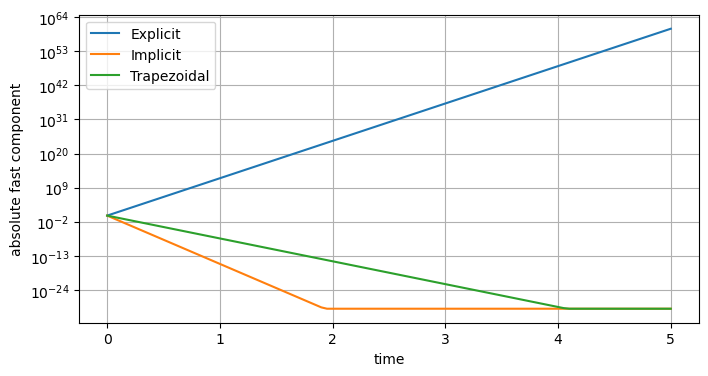

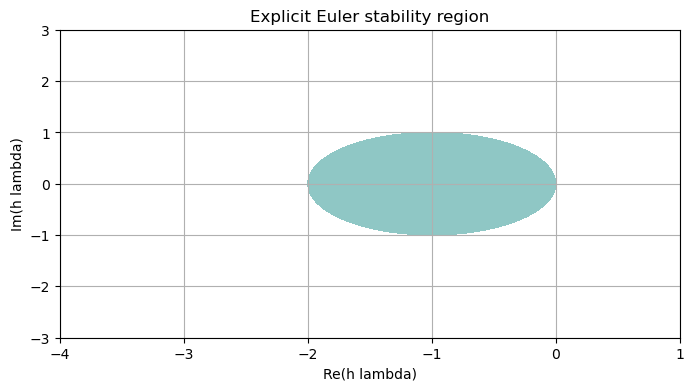

In [2]:
rates=np.array([1.,100.]);h=.05;t=np.arange(101)*h
for name,R in [("Explicit",1-h*rates),("Implicit",1/(1+h*rates)),("Trapezoidal",(1-h*rates/2)/(1+h*rates/2))]:
 values=R[None,:]**np.arange(101)[:,None]
 plt.semilogy(t,np.maximum(abs(values[:,1]),1e-30),label=name)
plt.xlabel("time");plt.ylabel("absolute fast component");plt.legend();plt.show()
assert abs(1-h*100)>1 and abs(1/(1+h*100))<1
xx,yy=np.meshgrid(np.linspace(-4,1,250),np.linspace(-3,3,250));z=xx+1j*yy
plt.contourf(xx,yy,abs(1+z),levels=[0,1],alpha=.5);plt.xlabel("Re(h lambda)");plt.ylabel("Im(h lambda)");plt.title("Explicit Euler stability region");plt.show()

## Read the result

The slow component would permit a much larger step than the explicit fast-mode stability restriction. Stability alone does not guarantee accurate resolution of the fast transient.

## Your turn

Compare backward Euler and trapezoidal decay when h*100=20. Why is A-stability insufficient to guarantee strong damping?

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.